In [ ]:
!wget https://nlp.stanford.edu/data/glove.6B.zip
!unzip glove.6B.zip -d .

--2026-05-01 13:24:44--  https://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2026-05-01 13:24:44--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glove.6B.zip        100%[===================>] 822.24M  5.11MB/s    in 2m 39s  

2026-05-01 13:27:23 (5.18 MB/s) - ‘glove.6B.zip’ saved [862182613/862182613]

Archive:  glove.6B.zip
  inflating: ./glove.6B.50d.txt      
  inflating: ./glove.6B.100d.txt     
  inflatin

In [ ]:
import pandas as pd
import re
from collections import Counter
import numpy as np
import torch

train_df = pd.read_csv('data/train.csv')
dev_df = pd.read_csv('data/dev.csv')
test_df = pd.read_csv('data/test.csv')

def tokenize_and_clean(text):
    text = text.lower()
    text = re.sub(r'@user', '', text)
    text = re.sub(r'[^a-z0-9\s]', '', text)
    return text.split()

train_df['tokens'] = train_df['sentence'].apply(tokenize_and_clean)
dev_df['tokens'] = dev_df['sentence'].apply(tokenize_and_clean)
test_df['tokens'] = test_df['sentence'].apply(tokenize_and_clean)

all_words = [word for tokens in train_df['tokens'] for word in tokens]
word_counts = Counter(all_words)

vocab = {'<PAD>': 0, '<UNK>': 1}
idx = 2
for word, count in word_counts.items():
    if count >= 2:
        vocab[word] = idx
        idx += 1

def load_glove_embeddings(glove_path, vocab, embedding_dim=100):
    embedding_matrix = np.zeros((len(vocab), embedding_dim))
    with open(glove_path, 'r', encoding='utf-8') as f:
        for line in f:
            values = line.split()
            word = values[0]
            if word in vocab:
                vector = np.asarray(values[1:], dtype='float32')
                embedding_matrix[vocab[word]] = vector

    embedding_matrix[vocab['<UNK>']] = np.random.normal(scale=0.6, size=(embedding_dim,))
    return torch.tensor(embedding_matrix, dtype=torch.float32)

pretrained_embeddings = load_glove_embeddings('glove.6B.100d.txt', vocab)

print("Vocab size:", len(vocab))
print("Embeddings shape:", pretrained_embeddings.shape)

Vocab size: 20796
Embeddings shape: torch.Size([20796, 100])


### **part1**


Testing LSTM config: {'hidden': 128, 'lr': 0.001, 'dropout': 0.3}

Training SentimentRNN | Bidirectional: False
Epoch [1/5], Training Loss: 0.3144, Time: 3.54s
Epoch [2/5], Training Loss: 0.1130, Time: 3.00s
Epoch [3/5], Training Loss: 0.0664, Time: 3.35s
Epoch [4/5], Training Loss: 0.0425, Time: 2.83s
Epoch [5/5], Training Loss: 0.0344, Time: 3.64s
Average training time per epoch: 3.27s

--- Evaluation Results on LSTM Dev Set ---
              precision    recall  f1-score   support

    negative     0.4104    0.5064    0.4534       312
     neutral     0.5893    0.5581    0.5733       869
    positive     0.6364    0.6154    0.6257       819

    accuracy                         0.5735      2000
   macro avg     0.5454    0.5600    0.5508      2000
weighted avg     0.5807    0.5735    0.5760      2000

Confusion Matrix:
[[158 106  48]
 [144 485 240]
 [ 83 232 504]]


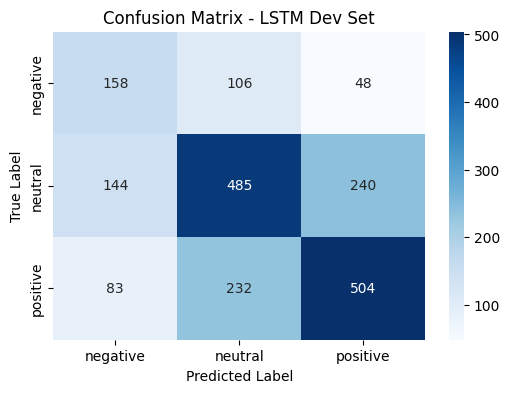


Testing LSTM config: {'hidden': 128, 'lr': 0.0005, 'dropout': 0.5}

Training SentimentRNN | Bidirectional: False
Epoch [1/5], Training Loss: 0.4021, Time: 2.96s
Epoch [2/5], Training Loss: 0.1578, Time: 3.52s
Epoch [3/5], Training Loss: 0.0920, Time: 2.88s
Epoch [4/5], Training Loss: 0.0616, Time: 2.89s
Epoch [5/5], Training Loss: 0.0461, Time: 2.90s
Average training time per epoch: 3.03s

--- Evaluation Results on LSTM Dev Set ---
              precision    recall  f1-score   support

    negative     0.4033    0.4679    0.4332       312
     neutral     0.5940    0.5270    0.5585       869
    positive     0.6159    0.6520    0.6335       819

    accuracy                         0.5690      2000
   macro avg     0.5378    0.5490    0.5417      2000
weighted avg     0.5732    0.5690    0.5697      2000

Confusion Matrix:
[[146 106  60]
 [138 458 273]
 [ 78 207 534]]


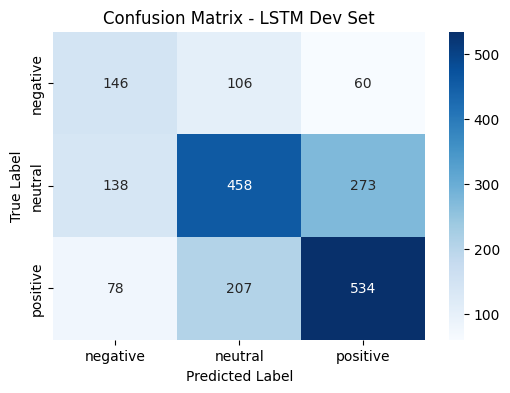


Testing LSTM config: {'hidden': 256, 'lr': 0.001, 'dropout': 0.3}

Training SentimentRNN | Bidirectional: False
Epoch [1/5], Training Loss: 0.2358, Time: 5.72s
Epoch [2/5], Training Loss: 0.0571, Time: 5.27s
Epoch [3/5], Training Loss: 0.0374, Time: 5.43s
Epoch [4/5], Training Loss: 0.0253, Time: 5.42s
Epoch [5/5], Training Loss: 0.0227, Time: 5.12s
Average training time per epoch: 5.39s

--- Evaluation Results on LSTM Dev Set ---
              precision    recall  f1-score   support

    negative     0.4317    0.4455    0.4385       312
     neutral     0.5894    0.5386    0.5628       869
    positive     0.6063    0.6545    0.6295       819

    accuracy                         0.5715      2000
   macro avg     0.5425    0.5462    0.5436      2000
weighted avg     0.5717    0.5715    0.5707      2000

Confusion Matrix:
[[139 109  64]
 [117 468 284]
 [ 66 217 536]]


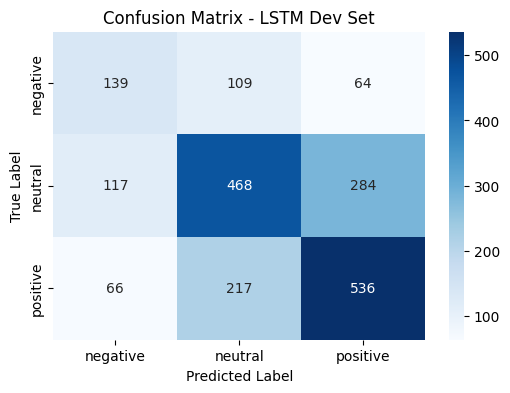


Testing LSTM config: {'hidden': 256, 'lr': 0.0005, 'dropout': 0.5}

Training SentimentRNN | Bidirectional: False
Epoch [1/5], Training Loss: 0.3168, Time: 6.14s
Epoch [2/5], Training Loss: 0.0880, Time: 5.09s
Epoch [3/5], Training Loss: 0.0446, Time: 5.31s
Epoch [4/5], Training Loss: 0.0318, Time: 5.38s
Epoch [5/5], Training Loss: 0.0224, Time: 5.78s
Average training time per epoch: 5.54s

--- Evaluation Results on LSTM Dev Set ---
              precision    recall  f1-score   support

    negative     0.4109    0.4583    0.4333       312
     neutral     0.5734    0.5754    0.5744       869
    positive     0.6346    0.6044    0.6191       819

    accuracy                         0.5690      2000
   macro avg     0.5396    0.5460    0.5423      2000
weighted avg     0.5731    0.5690    0.5707      2000

Confusion Matrix:
[[143 119  50]
 [134 500 235]
 [ 71 253 495]]


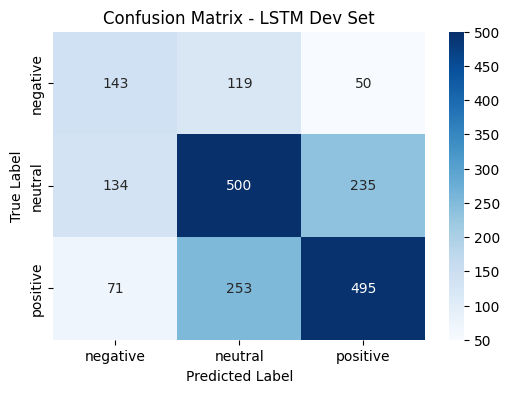


Testing BiLSTM config: {'hidden': 128, 'lr': 0.001, 'dropout': 0.3}

Training SentimentRNN | Bidirectional: True
Epoch [1/5], Training Loss: 0.1772, Time: 4.59s
Epoch [2/5], Training Loss: 0.0307, Time: 4.45s
Epoch [3/5], Training Loss: 0.0176, Time: 4.47s
Epoch [4/5], Training Loss: 0.0145, Time: 4.68s
Epoch [5/5], Training Loss: 0.0119, Time: 4.49s
Average training time per epoch: 4.54s

--- Evaluation Results on BiLSTM Dev Set ---
              precision    recall  f1-score   support

    negative     0.4208    0.5192    0.4648       312
     neutral     0.5903    0.5455    0.5670       869
    positive     0.6182    0.6129    0.6156       819

    accuracy                         0.5690      2000
   macro avg     0.5431    0.5592    0.5491      2000
weighted avg     0.5753    0.5690    0.5709      2000

Confusion Matrix:
[[162  98  52]
 [137 474 258]
 [ 86 231 502]]


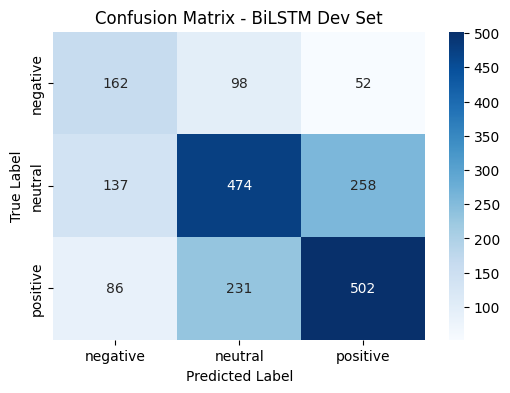


Testing BiLSTM config: {'hidden': 128, 'lr': 0.0005, 'dropout': 0.5}

Training SentimentRNN | Bidirectional: True
Epoch [1/5], Training Loss: 0.2421, Time: 4.61s
Epoch [2/5], Training Loss: 0.0462, Time: 7.47s
Epoch [3/5], Training Loss: 0.0216, Time: 4.48s
Epoch [4/5], Training Loss: 0.0169, Time: 4.59s
Epoch [5/5], Training Loss: 0.0129, Time: 4.53s
Average training time per epoch: 5.14s

--- Evaluation Results on BiLSTM Dev Set ---
              precision    recall  f1-score   support

    negative     0.4420    0.4519    0.4469       312
     neutral     0.5817    0.5938    0.5877       869
    positive     0.6297    0.6105    0.6200       819

    accuracy                         0.5785      2000
   macro avg     0.5512    0.5521    0.5515      2000
weighted avg     0.5796    0.5785    0.5789      2000

Confusion Matrix:
[[141 118  53]
 [112 516 241]
 [ 66 253 500]]


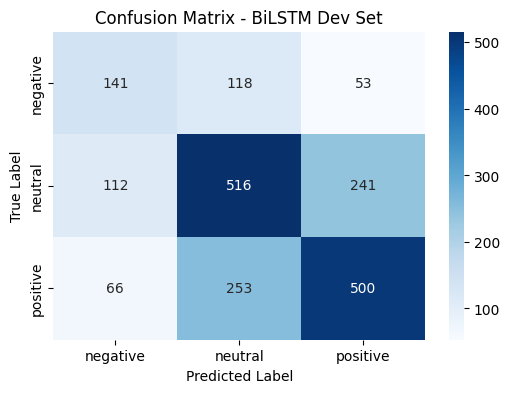


Testing BiLSTM config: {'hidden': 256, 'lr': 0.001, 'dropout': 0.3}

Training SentimentRNN | Bidirectional: True
Epoch [1/5], Training Loss: 0.1429, Time: 10.22s
Epoch [2/5], Training Loss: 0.0208, Time: 10.20s
Epoch [3/5], Training Loss: 0.0160, Time: 10.22s
Epoch [4/5], Training Loss: 0.0128, Time: 10.22s
Epoch [5/5], Training Loss: 0.0133, Time: 10.23s
Average training time per epoch: 10.22s

--- Evaluation Results on BiLSTM Dev Set ---
              precision    recall  f1-score   support

    negative     0.4352    0.4519    0.4434       312
     neutral     0.5832    0.5846    0.5839       869
    positive     0.6273    0.6166    0.6219       819

    accuracy                         0.5770      2000
   macro avg     0.5486    0.5510    0.5497      2000
weighted avg     0.5782    0.5770    0.5776      2000

Confusion Matrix:
[[141 115  56]
 [117 508 244]
 [ 66 248 505]]


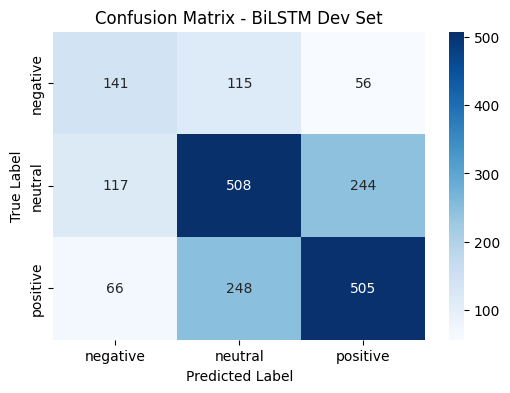


Testing BiLSTM config: {'hidden': 256, 'lr': 0.0005, 'dropout': 0.5}

Training SentimentRNN | Bidirectional: True
Epoch [1/5], Training Loss: 0.1972, Time: 10.24s
Epoch [2/5], Training Loss: 0.0284, Time: 11.55s
Epoch [3/5], Training Loss: 0.0156, Time: 10.30s
Epoch [4/5], Training Loss: 0.0115, Time: 10.27s
Epoch [5/5], Training Loss: 0.0090, Time: 10.29s
Average training time per epoch: 10.53s

--- Evaluation Results on BiLSTM Dev Set ---
              precision    recall  f1-score   support

    negative     0.4237    0.4808    0.4505       312
     neutral     0.5846    0.5765    0.5805       869
    positive     0.6248    0.6020    0.6132       819

    accuracy                         0.5720      2000
   macro avg     0.5444    0.5531    0.5481      2000
weighted avg     0.5760    0.5720    0.5736      2000

Confusion Matrix:
[[150 110  52]
 [124 501 244]
 [ 80 246 493]]


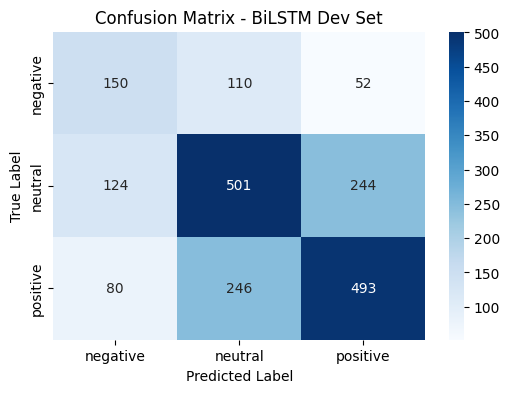

,Model,Hidden Size,Learning Rate,Dropout,Dev Accuracy,Dev Macro F1
0,LSTM,128,0.0010,0.3,0.5735,0.550785
1,LSTM,128,0.0005,0.5,0.5690,0.541741
2,LSTM,256,0.0010,0.3,0.5715,0.543600
3,LSTM,256,0.0005,0.5,0.5690,0.542284
4,BiLSTM,128,0.0010,0.3,0.5690,0.549136
5,BiLSTM,128,0.0005,0.5,0.5785,0.551524
6,BiLSTM,256,0.0010,0.3,0.5770,0.549742
7,BiLSTM,256,0.0005,0.5,0.5720,0.548056


,Hidden Size,Learning Rate,Dropout,Dev Accuracy,Dev Macro F1
Model,,,,,
BiLSTM,128,0.0005,0.5,0.5785,0.551524
LSTM,128,0.0010,0.3,0.5735,0.550785


In [ ]:
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MAX_LEN = 80
BATCH_SIZE = 64

def encode_and_pad(tokens, vocab, max_len):
    encoded = [vocab.get(word, vocab["<UNK>"]) for word in tokens]
    if len(encoded) < max_len:
        encoded += [vocab["<PAD>"]] * (max_len - len(encoded))
    else:
        encoded = encoded[:max_len]
    return encoded

label_mapping = {"negative": 0, "neutral": 1, "positive": 2}

train_inputs = torch.tensor([encode_and_pad(tokens, vocab, MAX_LEN) for tokens in train_df["tokens"]], dtype=torch.long).to(device)
dev_inputs = torch.tensor([encode_and_pad(tokens, vocab, MAX_LEN) for tokens in dev_df["tokens"]], dtype=torch.long).to(device)
test_inputs = torch.tensor([encode_and_pad(tokens, vocab, MAX_LEN) for tokens in test_df["tokens"]], dtype=torch.long).to(device)

train_labels = torch.tensor([label_mapping[label] for label in train_df["class"]], dtype=torch.long).to(device)
dev_labels = torch.tensor([label_mapping[label] for label in dev_df["class"]], dtype=torch.long).to(device)
test_labels = torch.tensor([label_mapping[label] for label in test_df["class"]], dtype=torch.long).to(device)

train_loader = DataLoader(TensorDataset(train_inputs, train_labels), batch_size=BATCH_SIZE, shuffle=True)
dev_loader = DataLoader(TensorDataset(dev_inputs, dev_labels), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(test_inputs, test_labels), batch_size=BATCH_SIZE)

pretrained_embeddings = pretrained_embeddings.to(device)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train_labels.cpu().numpy()
)

class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

class SentimentRNN(nn.Module):
    def __init__(self, embedding_dim, hidden_size, output_size, pretrained_embeddings, bidirectional, dropout_rate):
        super(SentimentRNN, self).__init__()
        self.embedding = nn.Embedding.from_pretrained(pretrained_embeddings, freeze=False)
        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_size,
            batch_first=True,
            bidirectional=bidirectional
        )
        self.dropout = nn.Dropout(dropout_rate)

        if bidirectional:
            self.fc = nn.Linear(hidden_size * 2, output_size)
        else:
            self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
      embedded = self.embedding(x)
      output, (hidden, cell) = self.lstm(embedded)

      mask = (x != 0).unsqueeze(-1).float()
      output = output * mask

      lengths = mask.sum(dim=1).clamp(min=1)

      pooled = output.sum(dim=1) / lengths

      out = self.dropout(pooled)
      out = self.fc(out)
      return out

def train_model(model, train_loader, criterion, optimizer, num_epochs):
    model.to(device)
    epoch_times = []

    print(f"\nTraining {model.__class__.__name__} | Bidirectional: {model.lstm.bidirectional}")

    for epoch in range(num_epochs):
        start_time = time.time()
        model.train()
        total_loss = 0

        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            total_loss += loss.item()

        epoch_time = time.time() - start_time
        epoch_times.append(epoch_time)

        print(
            f"Epoch [{epoch+1}/{num_epochs}], "
            f"Training Loss: {total_loss / len(train_loader):.4f}, "
            f"Time: {epoch_time:.2f}s"
        )

    avg_time = sum(epoch_times) / len(epoch_times)
    print(f"Average training time per epoch: {avg_time:.2f}s")
    return avg_time
def evaluate_model(model, dataloader, dataset_name):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    target_names = ["negative", "neutral", "positive"]

    print(f"\n--- Evaluation Results on {dataset_name} Set ---")

    report = classification_report(
        all_labels,
        all_preds,
        target_names=target_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )

    print(classification_report(
        all_labels,
        all_preds,
        target_names=target_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(all_labels, all_preds)

    print("Confusion Matrix:")
    print(cm)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"Confusion Matrix - {dataset_name} Set")
    plt.show()

    return report, cm

configs = [
    {"hidden": 128, "lr": 0.001, "dropout": 0.3},
    {"hidden": 128, "lr": 0.0005, "dropout": 0.5},
    {"hidden": 256, "lr": 0.001, "dropout": 0.3},
    {"hidden": 256, "lr": 0.0005, "dropout": 0.5}
]

tuning_results = []

for bidirectional in [False, True]:
    model_name = "BiLSTM" if bidirectional else "LSTM"

    for cfg in configs:
        print(f"\nTesting {model_name} config:", cfg)

        model = SentimentRNN(
            embedding_dim=100,
            hidden_size=cfg["hidden"],
            output_size=3,
            pretrained_embeddings=pretrained_embeddings,
            bidirectional=bidirectional,
            dropout_rate=cfg["dropout"]
        ).to(device)

        optimizer = optim.Adam(model.parameters(), lr=cfg["lr"])

        train_model(model, train_loader, criterion, optimizer, num_epochs=5)

        report, _ = evaluate_model(model, dev_loader, f"{model_name} Dev")

        tuning_results.append({
            "Model": model_name,
            "Hidden Size": cfg["hidden"],
            "Learning Rate": cfg["lr"],
            "Dropout": cfg["dropout"],
            "Dev Accuracy": report["accuracy"],
            "Dev Macro F1": report["macro avg"]["f1-score"]
        })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

best_configs = tuning_df.sort_values("Dev Macro F1", ascending=False).groupby("Model").first()
display(best_configs)


Training SentimentRNN | Bidirectional: False
Epoch [1/10], Training Loss: 0.2765, Time: 3.24s
Epoch [2/10], Training Loss: 0.0771, Time: 2.80s
Epoch [3/10], Training Loss: 0.0427, Time: 2.80s
Epoch [4/10], Training Loss: 0.0309, Time: 2.84s
Epoch [5/10], Training Loss: 0.0239, Time: 3.61s
Epoch [6/10], Training Loss: 0.0205, Time: 2.86s
Epoch [7/10], Training Loss: 0.0161, Time: 2.85s
Epoch [8/10], Training Loss: 0.0167, Time: 2.84s
Epoch [9/10], Training Loss: 0.0145, Time: 3.14s
Epoch [10/10], Training Loss: 0.0113, Time: 3.32s
Average training time per epoch: 3.03s

--- Evaluation Results on Development Set ---
              precision    recall  f1-score   support

    negative     0.4153    0.4872    0.4484       312
     neutral     0.5900    0.5581    0.5736       869
    positive     0.6305    0.6252    0.6278       819

    accuracy                         0.5745      2000
   macro avg     0.5453    0.5568    0.5499      2000
weighted avg     0.5794    0.5745    0.5763      20

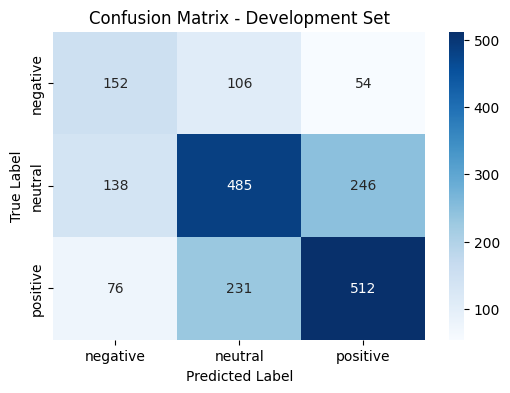


--- Evaluation Results on Test Set ---
              precision    recall  f1-score   support

    negative     0.5246    0.4569    0.4884      3972
     neutral     0.5638    0.5125    0.5370      5937
    positive     0.3904    0.5634    0.4612      2375

    accuracy                         0.5044     12284
   macro avg     0.4929    0.5110    0.4955     12284
weighted avg     0.5176    0.5044    0.5066     12284

Confusion Matrix:
[[1815 1587  570]
 [1375 3043 1519]
 [ 270  767 1338]]


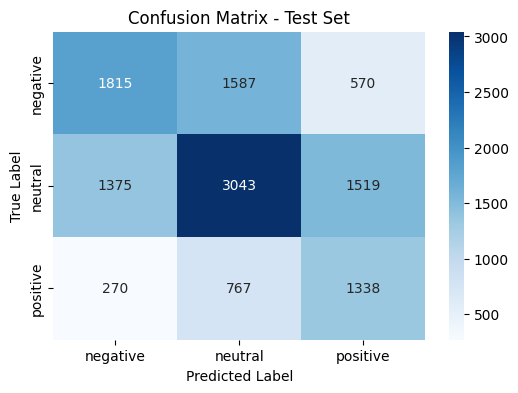


Training SentimentRNN | Bidirectional: True
Epoch [1/10], Training Loss: 0.2444, Time: 5.91s
Epoch [2/10], Training Loss: 0.0440, Time: 5.68s
Epoch [3/10], Training Loss: 0.0215, Time: 4.56s
Epoch [4/10], Training Loss: 0.0135, Time: 4.52s
Epoch [5/10], Training Loss: 0.0115, Time: 4.66s
Epoch [6/10], Training Loss: 0.0094, Time: 4.47s
Epoch [7/10], Training Loss: 0.0081, Time: 4.45s
Epoch [8/10], Training Loss: 0.0081, Time: 4.62s
Epoch [9/10], Training Loss: 0.0067, Time: 4.41s
Epoch [10/10], Training Loss: 0.0065, Time: 4.42s
Average training time per epoch: 4.77s

--- Evaluation Results on Development Set ---
              precision    recall  f1-score   support

    negative     0.4343    0.4872    0.4592       312
     neutral     0.5903    0.5604    0.5750       869
    positive     0.6218    0.6264    0.6241       819

    accuracy                         0.5760      2000
   macro avg     0.5488    0.5580    0.5528      2000
weighted avg     0.5789    0.5760    0.5770      200

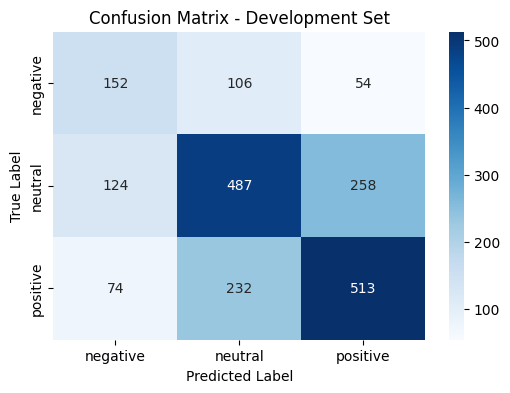


--- Evaluation Results on Test Set ---
              precision    recall  f1-score   support

    negative     0.5337    0.4778    0.5043      3972
     neutral     0.5690    0.5151    0.5407      5937
    positive     0.3962    0.5596    0.4640      2375

    accuracy                         0.5116     12284
   macro avg     0.4997    0.5175    0.5030     12284
weighted avg     0.5242    0.5116    0.5141     12284

Confusion Matrix:
[[1898 1532  542]
 [1396 3058 1483]
 [ 262  784 1329]]


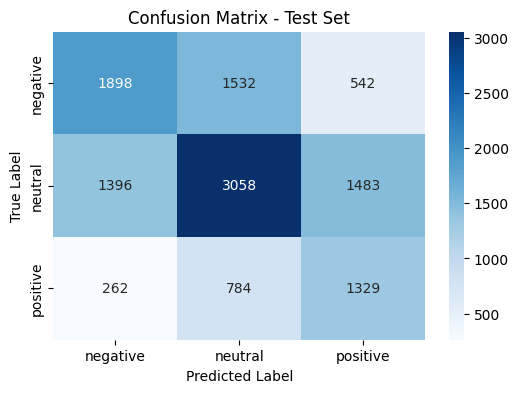

In [ ]:
LSTM_OUTPUT_SIZE = 3
LSTM_HIDDEN_SIZE = 128
LSTM_DROPOUT_RATE = 0.3
LSTM_LEARNING_RATE = 0.001
LSTM_EPOCHS = 10

lstm_model = SentimentRNN(
    embedding_dim=100,
    hidden_size=LSTM_HIDDEN_SIZE,
    output_size=LSTM_OUTPUT_SIZE,
    pretrained_embeddings=pretrained_embeddings,
    bidirectional=False,
    dropout_rate=LSTM_DROPOUT_RATE
).to(device)

optimizer_lstm = optim.Adam(lstm_model.parameters(), lr=LSTM_LEARNING_RATE)

lstm_avg_time = train_model(
    lstm_model,
    train_loader,
    criterion,
    optimizer_lstm,
    num_epochs=LSTM_EPOCHS
)

lstm_dev_report, lstm_dev_cm = evaluate_model(lstm_model, dev_loader, "Development")
lstm_test_report, lstm_test_cm = evaluate_model(lstm_model, test_loader, "Test")

BiLSTM_OUTPUT_SIZE = 3
BiLSTM_HIDDEN_SIZE = 128
BiLSTM_DROPOUT_RATE = 0.5
BiLSTM_LEARNING_RATE = 0.0005
BiLSTM_EPOCHS = 10

bilstm_model = SentimentRNN(
    embedding_dim=100,
    hidden_size=BiLSTM_HIDDEN_SIZE,
    output_size=BiLSTM_OUTPUT_SIZE,
    pretrained_embeddings=pretrained_embeddings,
    bidirectional=True,
    dropout_rate=BiLSTM_DROPOUT_RATE
).to(device)

optimizer_bilstm = optim.Adam(bilstm_model.parameters(), lr=BiLSTM_LEARNING_RATE)

bilstm_avg_time = train_model(
    bilstm_model,
    train_loader,
    criterion,
    optimizer_bilstm,
    num_epochs=BiLSTM_EPOCHS
)

bilstm_dev_report, bilstm_dev_cm = evaluate_model(bilstm_model, dev_loader, "Development")
bilstm_test_report, bilstm_test_cm = evaluate_model(bilstm_model, test_loader, "Test")

In [ ]:
import pandas as pd

def extract_metrics(report):
    return {
        "Accuracy": round(report["accuracy"], 4),
        "Macro Precision": round(report["macro avg"]["precision"], 4),
        "Macro Recall": round(report["macro avg"]["recall"], 4),
        "Macro F1": round(report["macro avg"]["f1-score"], 4)
    }

lstm_dev_metrics = extract_metrics(lstm_dev_report)
lstm_test_metrics = extract_metrics(lstm_test_report)

bilstm_dev_metrics = extract_metrics(bilstm_dev_report)
bilstm_test_metrics = extract_metrics(bilstm_test_report)

comparison_data = [
    ["LSTM (Dev)",
     lstm_dev_metrics["Accuracy"],
     lstm_dev_metrics["Macro Precision"],
     lstm_dev_metrics["Macro Recall"],
     lstm_dev_metrics["Macro F1"]],

    ["LSTM (Test)",
     lstm_test_metrics["Accuracy"],
     lstm_test_metrics["Macro Precision"],
     lstm_test_metrics["Macro Recall"],
     lstm_test_metrics["Macro F1"]],

    ["BiLSTM (Dev)",
     bilstm_dev_metrics["Accuracy"],
     bilstm_dev_metrics["Macro Precision"],
     bilstm_dev_metrics["Macro Recall"],
     bilstm_dev_metrics["Macro F1"]],

    ["BiLSTM (Test)",
     bilstm_test_metrics["Accuracy"],
     bilstm_test_metrics["Macro Precision"],
     bilstm_test_metrics["Macro Recall"],
     bilstm_test_metrics["Macro F1"]],
]

columns = ["Model", "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]

comparison_df = pd.DataFrame(comparison_data, columns=columns)

print("\n=== Part 1: LSTM vs BiLSTM Comparison ===")
display(comparison_df)


=== Part 1: LSTM vs BiLSTM Comparison ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,LSTM (Dev),0.5745,0.5453,0.5568,0.5499
1,LSTM (Test),0.5044,0.4929,0.5110,0.4955
2,BiLSTM (Dev),0.5760,0.5488,0.5580,0.5528
3,BiLSTM (Test),0.5116,0.4997,0.5175,0.5030


### **Part2**


Testing BiRNN config: {'lr': 0.001, 'dropout': 0.3}

Training BiRNN
Epoch [1/5], Training Loss: 0.4006, Time: 3.93s
Epoch [2/5], Training Loss: 0.2427, Time: 3.64s
Epoch [3/5], Training Loss: 0.1818, Time: 2.81s
Epoch [4/5], Training Loss: 0.1397, Time: 3.44s
Epoch [5/5], Training Loss: 0.1097, Time: 2.96s
Average training time per epoch: 3.36s

--- Evaluation Results on BiRNN Dev Set ---
              precision    recall  f1-score   support

    negative     0.4261    0.4808    0.4518       312
     neutral     0.5845    0.5455    0.5643       869
    positive     0.6213    0.6349    0.6280       819

    accuracy                         0.5720      2000
   macro avg     0.5440    0.5537    0.5480      2000
weighted avg     0.5748    0.5720    0.5728      2000

Confusion Matrix:
[[150 111  51]
 [129 474 266]
 [ 73 226 520]]


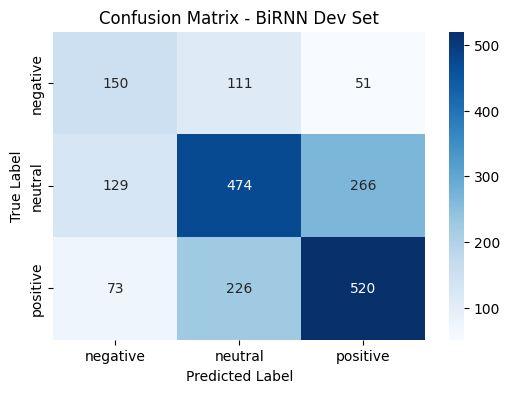


Testing BiRNN config: {'lr': 0.0005, 'dropout': 0.3}

Training BiRNN
Epoch [1/5], Training Loss: 0.3602, Time: 3.86s
Epoch [2/5], Training Loss: 0.1854, Time: 2.82s
Epoch [3/5], Training Loss: 0.1393, Time: 3.50s
Epoch [4/5], Training Loss: 0.1054, Time: 3.10s
Epoch [5/5], Training Loss: 0.0852, Time: 2.68s
Average training time per epoch: 3.19s

--- Evaluation Results on BiRNN Dev Set ---
              precision    recall  f1-score   support

    negative     0.4197    0.4776    0.4468       312
     neutral     0.5873    0.5765    0.5819       869
    positive     0.6402    0.6190    0.6294       819

    accuracy                         0.5785      2000
   macro avg     0.5491    0.5577    0.5527      2000
weighted avg     0.5828    0.5785    0.5803      2000

Confusion Matrix:
[[149 117  46]
 [129 501 239]
 [ 77 235 507]]


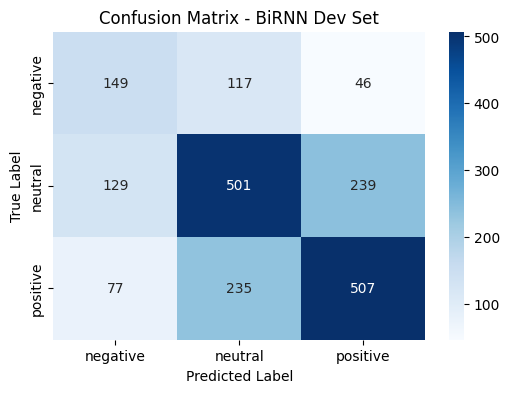


Testing BiRNN config: {'lr': 0.001, 'dropout': 0.5}

Training BiRNN
Epoch [1/5], Training Loss: 0.3249, Time: 2.69s
Epoch [2/5], Training Loss: 0.1750, Time: 3.13s
Epoch [3/5], Training Loss: 0.1435, Time: 3.10s
Epoch [4/5], Training Loss: 0.1257, Time: 2.70s
Epoch [5/5], Training Loss: 0.1041, Time: 2.69s
Average training time per epoch: 2.86s

--- Evaluation Results on BiRNN Dev Set ---
              precision    recall  f1-score   support

    negative     0.4131    0.5865    0.4848       312
     neutral     0.5897    0.5788    0.5842       869
    positive     0.6577    0.5653    0.6080       819

    accuracy                         0.5745      2000
   macro avg     0.5535    0.5769    0.5590      2000
weighted avg     0.5900    0.5745    0.5784      2000

Confusion Matrix:
[[183  94  35]
 [160 503 206]
 [100 256 463]]


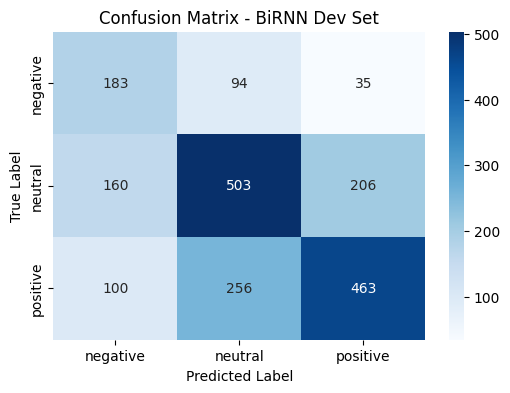


Testing BiRNN config: {'lr': 0.0005, 'dropout': 0.5}

Training BiRNN
Epoch [1/5], Training Loss: 0.3196, Time: 2.69s
Epoch [2/5], Training Loss: 0.1434, Time: 3.52s
Epoch [3/5], Training Loss: 0.1073, Time: 2.77s
Epoch [4/5], Training Loss: 0.0873, Time: 2.67s
Epoch [5/5], Training Loss: 0.0731, Time: 2.66s
Average training time per epoch: 2.86s

--- Evaluation Results on BiRNN Dev Set ---
              precision    recall  f1-score   support

    negative     0.5066    0.3718    0.4288       312
     neutral     0.5905    0.5558    0.5726       869
    positive     0.6086    0.7082    0.6546       819

    accuracy                         0.5895      2000
   macro avg     0.5685    0.5453    0.5520      2000
weighted avg     0.5848    0.5895    0.5838      2000

Confusion Matrix:
[[116 128  68]
 [ 81 483 305]
 [ 32 207 580]]


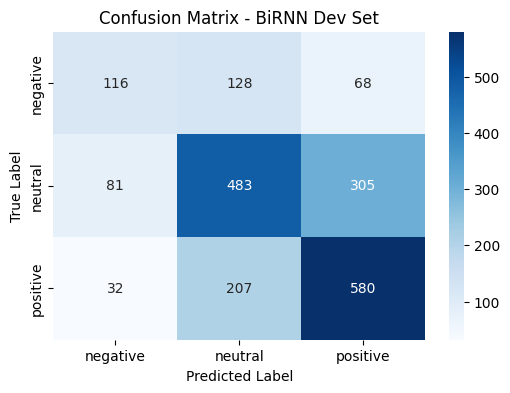

,Model,Hidden Size,Learning Rate,Dropout,Batch Size,Optimizer,Dev Accuracy,Dev Macro F1
0,BiRNN,128,0.0010,0.3,64,Adam,0.5720,0.548037
1,BiRNN,128,0.0005,0.3,64,Adam,0.5785,0.552694
2,BiRNN,128,0.0010,0.5,64,Adam,0.5745,0.558994
3,BiRNN,128,0.0005,0.5,64,Adam,0.5895,0.552026


In [ ]:
class SentimentBiRNN(nn.Module):
    def __init__(self, embedding_dim, hidden_size, output_size, pretrained_embeddings, dropout_rate):
        super(SentimentBiRNN, self).__init__()
        self.embedding = nn.Embedding.from_pretrained(pretrained_embeddings, freeze=False)
        self.rnn = nn.RNN(
            embedding_dim,
            hidden_size,
            batch_first=True,
            bidirectional=True,
            nonlinearity="tanh"
        )
        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(hidden_size * 2, output_size)

    def forward(self, x):
        embedded = self.embedding(x)
        output, hidden = self.rnn(embedded)

        mask = (x != 0).unsqueeze(-1).float()
        output = output * mask
        lengths = mask.sum(dim=1).clamp(min=1)

        pooled = output.sum(dim=1) / lengths

        out = self.dropout(pooled)
        out = self.fc(out)
        return out

def train_birnn_model(model, train_loader, criterion, optimizer, num_epochs):
    model.to(device)
    epoch_times = []

    print("\nTraining BiRNN")

    for epoch in range(num_epochs):
        start_time = time.time()
        model.train()
        total_loss = 0

        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            total_loss += loss.item()

        epoch_time = time.time() - start_time
        epoch_times.append(epoch_time)

        print(
            f"Epoch [{epoch+1}/{num_epochs}], "
            f"Training Loss: {total_loss / len(train_loader):.4f}, "
            f"Time: {epoch_time:.2f}s"
        )

    avg_time = sum(epoch_times) / len(epoch_times)
    print(f"Average training time per epoch: {avg_time:.2f}s")
    return avg_time

def evaluate_birnn_model(model, dataloader, dataset_name):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    target_names = ["negative", "neutral", "positive"]

    print(f"\n--- Evaluation Results on {dataset_name} Set ---")

    report = classification_report(
        all_labels,
        all_preds,
        target_names=target_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )

    print(classification_report(
        all_labels,
        all_preds,
        target_names=target_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(all_labels, all_preds)

    print("Confusion Matrix:")
    print(cm)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"Confusion Matrix - {dataset_name} Set")
    plt.show()

    return report, cm

birnn_configs = [
    {"lr": 0.001, "dropout": 0.3},
    {"lr": 0.0005, "dropout": 0.3},
    {"lr": 0.001, "dropout": 0.5},
    {"lr": 0.0005, "dropout": 0.5}
]

birnn_tuning_results = []

for cfg in birnn_configs:
    print("\nTesting BiRNN config:", cfg)

    birnn_temp = SentimentBiRNN(
        embedding_dim=100,
        hidden_size=BiLSTM_HIDDEN_SIZE,
        output_size=3,
        pretrained_embeddings=pretrained_embeddings,
        dropout_rate=cfg["dropout"]
    ).to(device)

    optimizer_birnn_temp = optim.Adam(birnn_temp.parameters(), lr=cfg["lr"])

    train_birnn_model(
        birnn_temp,
        train_loader,
        criterion,
        optimizer_birnn_temp,
        num_epochs=5
    )

    report, _ = evaluate_birnn_model(birnn_temp, dev_loader, "BiRNN Dev")

    birnn_tuning_results.append({
        "Model": "BiRNN",
        "Hidden Size": BiLSTM_HIDDEN_SIZE,
        "Learning Rate": cfg["lr"],
        "Dropout": cfg["dropout"],
        "Batch Size": BATCH_SIZE,
        "Optimizer": "Adam",
        "Dev Accuracy": report["accuracy"],
        "Dev Macro F1": report["macro avg"]["f1-score"]
    })

birnn_tuning_df = pd.DataFrame(birnn_tuning_results)
display(birnn_tuning_df)

Best BiRNN config:
Model               BiRNN
Hidden Size           128
Learning Rate       0.001
Dropout               0.5
Batch Size             64
Optimizer            Adam
Dev Accuracy       0.5745
Dev Macro F1     0.558994
Name: 2, dtype: object

Training BiRNN
Epoch [1/10], Training Loss: 0.2971, Time: 2.94s
Epoch [2/10], Training Loss: 0.1455, Time: 3.26s
Epoch [3/10], Training Loss: 0.1199, Time: 2.64s
Epoch [4/10], Training Loss: 0.1045, Time: 2.67s
Epoch [5/10], Training Loss: 0.0902, Time: 2.69s
Epoch [6/10], Training Loss: 0.0771, Time: 3.08s
Epoch [7/10], Training Loss: 0.0663, Time: 3.14s
Epoch [8/10], Training Loss: 0.0609, Time: 2.69s
Epoch [9/10], Training Loss: 0.0557, Time: 2.74s
Epoch [10/10], Training Loss: 0.0513, Time: 2.70s
Average training time per epoch: 2.86s

--- Evaluation Results on Development Set ---
              precision    recall  f1-score   support

    negative     0.4056    0.5096    0.4517       312
     neutral     0.5979    0.5765    0.5870     

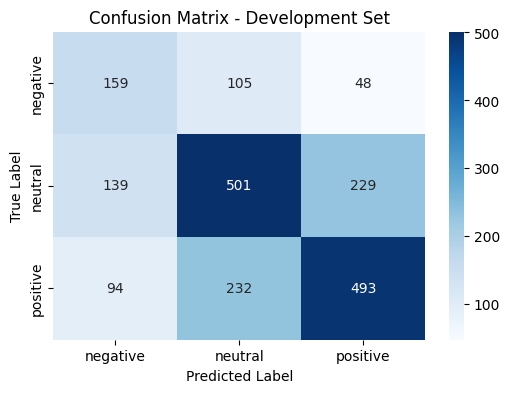


--- Evaluation Results on Test Set ---
              precision    recall  f1-score   support

    negative     0.5029    0.5267    0.5145      3972
     neutral     0.5730    0.4682    0.5153      5937
    positive     0.4065    0.5600    0.4710      2375

    accuracy                         0.5049     12284
   macro avg     0.4941    0.5183    0.5003     12284
weighted avg     0.5181    0.5049    0.5065     12284

Confusion Matrix:
[[2092 1369  511]
 [1726 2780 1431]
 [ 342  703 1330]]


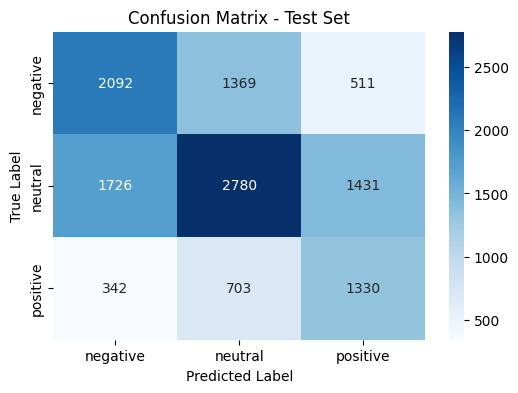

In [ ]:
best_birnn_config = birnn_tuning_df.sort_values("Dev Macro F1", ascending=False).iloc[0]
print("Best BiRNN config:")
print(best_birnn_config)

BiRNN_HIDDEN_SIZE = BiLSTM_HIDDEN_SIZE
BiRNN_OUTPUT_SIZE = 3
BiRNN_DROPOUT_RATE = float(best_birnn_config["Dropout"])
BiRNN_LEARNING_RATE = float(best_birnn_config["Learning Rate"])
BiRNN_EPOCHS = 10

birnn_model = SentimentBiRNN(
    embedding_dim=100,
    hidden_size=BiRNN_HIDDEN_SIZE,
    output_size=BiRNN_OUTPUT_SIZE,
    pretrained_embeddings=pretrained_embeddings,
    dropout_rate=BiRNN_DROPOUT_RATE
).to(device)

optimizer_birnn = optim.Adam(birnn_model.parameters(), lr=BiRNN_LEARNING_RATE)

birnn_avg_time = train_birnn_model(
    birnn_model,
    train_loader,
    criterion,
    optimizer_birnn,
    num_epochs=BiRNN_EPOCHS
)

birnn_dev_report, birnn_dev_cm = evaluate_birnn_model(birnn_model, dev_loader, "Development")
birnn_test_report, birnn_test_cm = evaluate_birnn_model(birnn_model, test_loader, "Test")

In [ ]:
def extract_metrics(report):
    return {
        "Accuracy": round(report["accuracy"], 4),
        "Macro Precision": round(report["macro avg"]["precision"], 4),
        "Macro Recall": round(report["macro avg"]["recall"], 4),
        "Macro F1": round(report["macro avg"]["f1-score"], 4)
    }

bilstm_dev_metrics = extract_metrics(bilstm_dev_report)
bilstm_test_metrics = extract_metrics(bilstm_test_report)

birnn_dev_metrics = extract_metrics(birnn_dev_report)
birnn_test_metrics = extract_metrics(birnn_test_report)

part2_comparison_data = [
    ["BiLSTM (Dev)",
     bilstm_dev_metrics["Accuracy"],
     bilstm_dev_metrics["Macro Precision"],
     bilstm_dev_metrics["Macro Recall"],
     bilstm_dev_metrics["Macro F1"],
     round(bilstm_avg_time, 2)],

    ["BiLSTM (Test)",
     bilstm_test_metrics["Accuracy"],
     bilstm_test_metrics["Macro Precision"],
     bilstm_test_metrics["Macro Recall"],
     bilstm_test_metrics["Macro F1"],
     round(bilstm_avg_time, 2)],

    ["BiRNN (Dev)",
     birnn_dev_metrics["Accuracy"],
     birnn_dev_metrics["Macro Precision"],
     birnn_dev_metrics["Macro Recall"],
     birnn_dev_metrics["Macro F1"],
     round(birnn_avg_time, 2)],

    ["BiRNN (Test)",
     birnn_test_metrics["Accuracy"],
     birnn_test_metrics["Macro Precision"],
     birnn_test_metrics["Macro Recall"],
     birnn_test_metrics["Macro F1"],
     round(birnn_avg_time, 2)]
]

part2_columns = [
    "Model",
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Avg Time/Epoch"
]

part2_comparison_df = pd.DataFrame(part2_comparison_data, columns=part2_columns)

print("\n=== Part 2: BiLSTM vs BiRNN Comparison ===")
display(part2_comparison_df)


=== Part 2: BiLSTM vs BiRNN Comparison ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Avg Time/Epoch
0,BiLSTM (Dev),0.5760,0.5488,0.5580,0.5528,4.77
1,BiLSTM (Test),0.5116,0.4997,0.5175,0.5030,4.77
2,BiRNN (Dev),0.5765,0.5479,0.5627,0.5531,2.86
3,BiRNN (Test),0.5049,0.4941,0.5183,0.5003,2.86


### **Part3**


Testing attention config: {'lr': 0.001, 'epochs': 5, 'attention_dim': 64}

Training BiLSTM with Additive Attention
Epoch [1/5], Training Loss: 0.1651, Time: 5.33s
Epoch [2/5], Training Loss: 0.0381, Time: 8.86s
Epoch [3/5], Training Loss: 0.0232, Time: 6.76s
Epoch [4/5], Training Loss: 0.0168, Time: 5.10s
Epoch [5/5], Training Loss: 0.0148, Time: 4.83s
Average training time per epoch: 6.18s

--- Evaluation Results on BiLSTM Attention Dev Set ---
              precision    recall  f1-score   support

    negative     0.4338    0.4936    0.4618       312
     neutral     0.5904    0.5673    0.5786       869
    positive     0.6247    0.6178    0.6212       819

    accuracy                         0.5765      2000
   macro avg     0.5496    0.5596    0.5539      2000
weighted avg     0.5800    0.5765    0.5779      2000

Confusion Matrix:
[[154  97  61]
 [133 493 243]
 [ 68 245 506]]


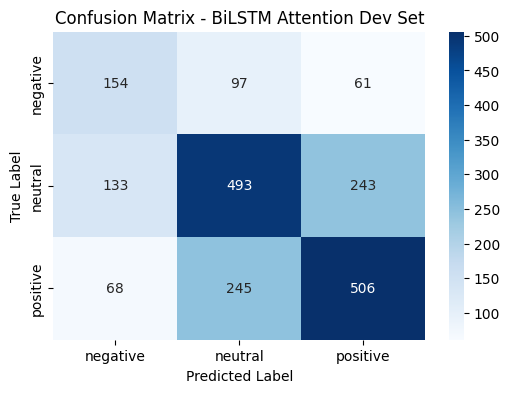


Testing attention config: {'lr': 0.0005, 'epochs': 5, 'attention_dim': 64}

Training BiLSTM with Additive Attention
Epoch [1/5], Training Loss: 0.2071, Time: 4.79s
Epoch [2/5], Training Loss: 0.0441, Time: 4.91s
Epoch [3/5], Training Loss: 0.0242, Time: 5.32s
Epoch [4/5], Training Loss: 0.0177, Time: 7.01s
Epoch [5/5], Training Loss: 0.0148, Time: 6.84s
Average training time per epoch: 5.77s

--- Evaluation Results on BiLSTM Attention Dev Set ---
              precision    recall  f1-score   support

    negative     0.4269    0.4776    0.4508       312
     neutral     0.5753    0.5581    0.5666       869
    positive     0.6139    0.6056    0.6097       819

    accuracy                         0.5650      2000
   macro avg     0.5387    0.5471    0.5424      2000
weighted avg     0.5680    0.5650    0.5662      2000

Confusion Matrix:
[[149 109  54]
 [126 485 258]
 [ 74 249 496]]


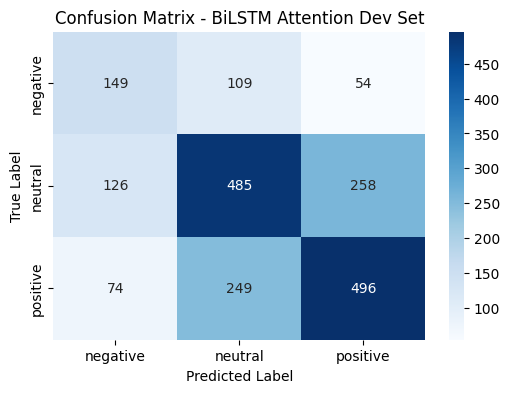


Testing attention config: {'lr': 0.001, 'epochs': 10, 'attention_dim': 128}

Training BiLSTM with Additive Attention
Epoch [1/10], Training Loss: 0.1526, Time: 5.43s
Epoch [2/10], Training Loss: 0.0307, Time: 5.73s
Epoch [3/10], Training Loss: 0.0191, Time: 5.19s
Epoch [4/10], Training Loss: 0.0170, Time: 4.96s
Epoch [5/10], Training Loss: 0.0131, Time: 4.90s
Epoch [6/10], Training Loss: 0.0135, Time: 5.07s
Epoch [7/10], Training Loss: 0.0123, Time: 5.03s
Epoch [8/10], Training Loss: 0.0098, Time: 4.88s
Epoch [9/10], Training Loss: 0.0104, Time: 4.90s
Epoch [10/10], Training Loss: 0.0093, Time: 5.01s
Average training time per epoch: 5.11s

--- Evaluation Results on BiLSTM Attention Dev Set ---
              precision    recall  f1-score   support

    negative     0.4261    0.4808    0.4518       312
     neutral     0.5805    0.5558    0.5679       869
    positive     0.6189    0.6166    0.6177       819

    accuracy                         0.5690      2000
   macro avg     0.5418 

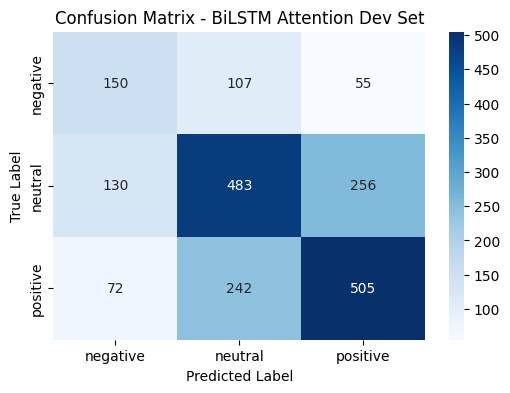


Testing attention config: {'lr': 0.0005, 'epochs': 10, 'attention_dim': 128}

Training BiLSTM with Additive Attention
Epoch [1/10], Training Loss: 0.2048, Time: 4.86s
Epoch [2/10], Training Loss: 0.0359, Time: 4.94s
Epoch [3/10], Training Loss: 0.0192, Time: 5.27s
Epoch [4/10], Training Loss: 0.0143, Time: 4.82s
Epoch [5/10], Training Loss: 0.0110, Time: 4.97s
Epoch [6/10], Training Loss: 0.0094, Time: 4.82s
Epoch [7/10], Training Loss: 0.0086, Time: 4.82s
Epoch [8/10], Training Loss: 0.0075, Time: 4.98s
Epoch [9/10], Training Loss: 0.0073, Time: 4.81s
Epoch [10/10], Training Loss: 0.0068, Time: 4.85s
Average training time per epoch: 4.91s

--- Evaluation Results on BiLSTM Attention Dev Set ---
              precision    recall  f1-score   support

    negative     0.4234    0.4519    0.4372       312
     neutral     0.5723    0.5604    0.5663       869
    positive     0.6127    0.6105    0.6116       819

    accuracy                         0.5640      2000
   macro avg     0.5361

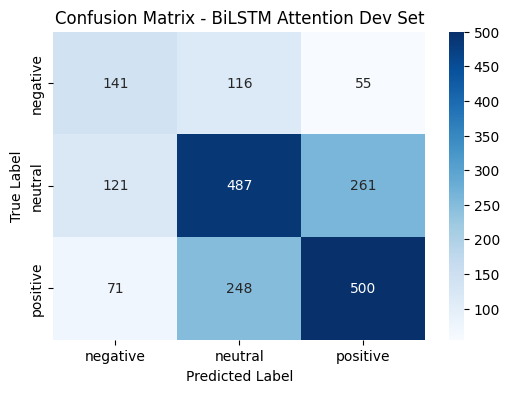

,Learning Rate,Epochs,Attention Dim,Dev Accuracy,Dev Macro F1
0,0.0010,5,64,0.5765,0.553883
1,0.0005,5,64,0.5650,0.542377
2,0.0010,10,128,0.5690,0.545815
3,0.0005,10,128,0.5640,0.538370


Best Attention Config:
Learning Rate     0.001000
Epochs            5.000000
Attention Dim    64.000000
Dev Accuracy      0.576500
Dev Macro F1      0.553883
Name: 0, dtype: float64


In [ ]:
class BiLSTMAttention(nn.Module):
    def __init__(self, embedding_dim, hidden_size, output_size, pretrained_embeddings, dropout_rate, attention_dim):
        super(BiLSTMAttention, self).__init__()

        self.embedding = nn.Embedding.from_pretrained(pretrained_embeddings, freeze=False)

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_size,
            batch_first=True,
            bidirectional=True
        )

        self.attention_W = nn.Linear(hidden_size * 2, attention_dim)
        self.attention_v = nn.Linear(attention_dim, 1, bias=False)

        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(hidden_size * 2, output_size)

    def forward(self, x, return_attention=False):
        embedded = self.embedding(x)
        outputs, (hidden, cell) = self.lstm(embedded)

        scores = self.attention_v(torch.tanh(self.attention_W(outputs))).squeeze(-1)

        mask = (x != 0)
        scores = scores.masked_fill(mask == 0, -1e9)

        attention_weights = torch.softmax(scores, dim=1)

        context = torch.bmm(attention_weights.unsqueeze(1), outputs).squeeze(1)

        out = self.dropout(context)
        logits = self.fc(out)

        if return_attention:
            return logits, attention_weights

        return logits

def train_attention_model(model, train_loader, criterion, optimizer, num_epochs):
    model.to(device)
    epoch_times = []

    print("\nTraining BiLSTM with Additive Attention")

    for epoch in range(num_epochs):
        start_time = time.time()
        model.train()
        total_loss = 0

        for inputs, labels in train_loader:
            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            total_loss += loss.item()

        epoch_time = time.time() - start_time
        epoch_times.append(epoch_time)

        print(
            f"Epoch [{epoch+1}/{num_epochs}], "
            f"Training Loss: {total_loss / len(train_loader):.4f}, "
            f"Time: {epoch_time:.2f}s"
        )

    avg_time = sum(epoch_times) / len(epoch_times)
    print(f"Average training time per epoch: {avg_time:.2f}s")
    return avg_time

def evaluate_attention_model(model, dataloader, dataset_name):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    target_names = ["negative", "neutral", "positive"]

    print(f"\n--- Evaluation Results on {dataset_name} Set ---")

    report = classification_report(
        all_labels,
        all_preds,
        target_names=target_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )

    print(classification_report(
        all_labels,
        all_preds,
        target_names=target_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(all_labels, all_preds)

    print("Confusion Matrix:")
    print(cm)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"Confusion Matrix - {dataset_name} Set")
    plt.show()

    return report, cm

attention_configs = [
    {"lr": 0.001, "epochs": 5, "attention_dim": 64},
    {"lr": 0.0005, "epochs": 5, "attention_dim": 64},
    {"lr": 0.001, "epochs": 10, "attention_dim": 128},
    {"lr": 0.0005, "epochs": 10, "attention_dim": 128},
]

attention_tuning_results = []

for cfg in attention_configs:
    print("\nTesting attention config:", cfg)

    temp_attention_model = BiLSTMAttention(
        embedding_dim=100,
        hidden_size=BiLSTM_HIDDEN_SIZE,
        output_size=3,
        pretrained_embeddings=pretrained_embeddings,
        dropout_rate=BiLSTM_DROPOUT_RATE,
        attention_dim=cfg["attention_dim"]
    ).to(device)

    optimizer_temp = optim.Adam(temp_attention_model.parameters(), lr=cfg["lr"])

    train_attention_model(
        temp_attention_model,
        train_loader,
        criterion,
        optimizer_temp,
        num_epochs=cfg["epochs"]
    )

    report, _ = evaluate_attention_model(
        temp_attention_model,
        dev_loader,
        "BiLSTM Attention Dev"
    )

    attention_tuning_results.append({
        "Learning Rate": cfg["lr"],
        "Epochs": cfg["epochs"],
        "Attention Dim": cfg["attention_dim"],
        "Dev Accuracy": report["accuracy"],
        "Dev Macro F1": report["macro avg"]["f1-score"]
    })

attention_tuning_df = pd.DataFrame(attention_tuning_results)
display(attention_tuning_df)

best_attention_config = attention_tuning_df.sort_values(
    "Dev Macro F1",
    ascending=False
).iloc[0]

print("Best Attention Config:")
print(best_attention_config)


Training BiLSTM with Additive Attention
Epoch [1/5], Training Loss: 0.1459, Time: 4.85s
Epoch [2/5], Training Loss: 0.0242, Time: 4.75s
Epoch [3/5], Training Loss: 0.0149, Time: 4.80s
Epoch [4/5], Training Loss: 0.0143, Time: 4.83s
Epoch [5/5], Training Loss: 0.0118, Time: 4.73s
Average training time per epoch: 4.79s

--- Evaluation Results on Development Set ---
              precision    recall  f1-score   support

    negative     0.4382    0.4776    0.4571       312
     neutral     0.5861    0.5834    0.5848       869
    positive     0.6277    0.6093    0.6183       819

    accuracy                         0.5775      2000
   macro avg     0.5507    0.5568    0.5534      2000
weighted avg     0.5801    0.5775    0.5786      2000

Confusion Matrix:
[[149 109  54]
 [120 507 242]
 [ 71 249 499]]


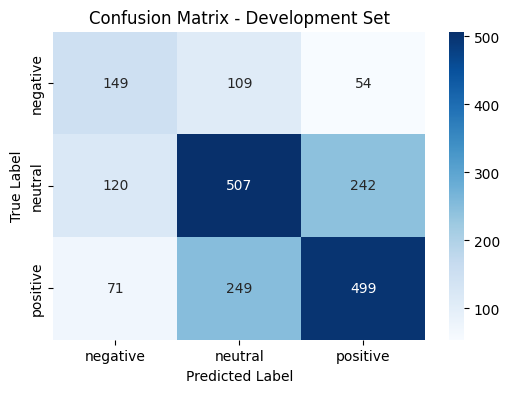


--- Evaluation Results on Test Set ---
              precision    recall  f1-score   support

    negative     0.5313    0.4635    0.4951      3972
     neutral     0.5646    0.5189    0.5408      5937
    positive     0.3959    0.5604    0.4640      2375

    accuracy                         0.5090     12284
   macro avg     0.4973    0.5143    0.5000     12284
weighted avg     0.5212    0.5090    0.5112     12284

Confusion Matrix:
[[1841 1588  543]
 [1368 3081 1488]
 [ 256  788 1331]]


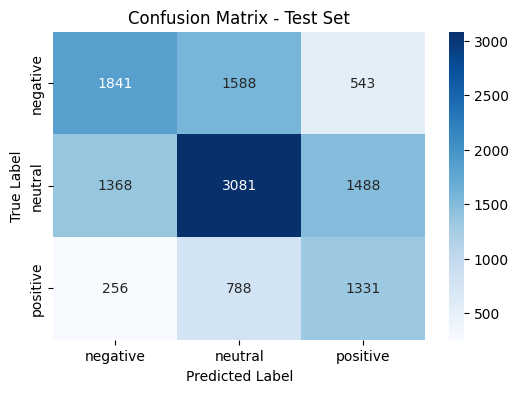

In [ ]:
ATTENTION_LEARNING_RATE = float(best_attention_config["Learning Rate"])
ATTENTION_EPOCHS = int(best_attention_config["Epochs"])
ATTENTION_DIM = int(best_attention_config["Attention Dim"])

attention_model = BiLSTMAttention(
    embedding_dim=100,
    hidden_size=BiLSTM_HIDDEN_SIZE,
    output_size=3,
    pretrained_embeddings=pretrained_embeddings,
    dropout_rate=BiLSTM_DROPOUT_RATE,
    attention_dim=ATTENTION_DIM
).to(device)

optimizer_attention = optim.Adam(
    attention_model.parameters(),
    lr=ATTENTION_LEARNING_RATE
)

attention_avg_time = train_attention_model(
    attention_model,
    train_loader,
    criterion,
    optimizer_attention,
    num_epochs=ATTENTION_EPOCHS
)

attention_dev_report, attention_dev_cm = evaluate_attention_model(
    attention_model,
    dev_loader,
    "Development"
)

attention_test_report, attention_test_cm = evaluate_attention_model(
    attention_model,
    test_loader,
    "Test"
)

In [ ]:
bilstm_dev_metrics = extract_metrics(bilstm_dev_report)
bilstm_test_metrics = extract_metrics(bilstm_test_report)

attention_dev_metrics = extract_metrics(attention_dev_report)
attention_test_metrics = extract_metrics(attention_test_report)

part3_comparison_data = [
    ["BiLSTM (Dev)",
     bilstm_dev_metrics["Accuracy"],
     bilstm_dev_metrics["Macro Precision"],
     bilstm_dev_metrics["Macro Recall"],
     bilstm_dev_metrics["Macro F1"],
     round(bilstm_avg_time, 2)],

    ["BiLSTM (Test)",
     bilstm_test_metrics["Accuracy"],
     bilstm_test_metrics["Macro Precision"],
     bilstm_test_metrics["Macro Recall"],
     bilstm_test_metrics["Macro F1"],
     round(bilstm_avg_time, 2)],

    ["BiLSTM + Attention (Dev)",
     attention_dev_metrics["Accuracy"],
     attention_dev_metrics["Macro Precision"],
     attention_dev_metrics["Macro Recall"],
     attention_dev_metrics["Macro F1"],
     round(attention_avg_time, 2)],

    ["BiLSTM + Attention (Test)",
     attention_test_metrics["Accuracy"],
     attention_test_metrics["Macro Precision"],
     attention_test_metrics["Macro Recall"],
     attention_test_metrics["Macro F1"],
     round(attention_avg_time, 2)]
]

part3_columns = [
    "Model",
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Avg Time/Epoch"
]

part3_comparison_df = pd.DataFrame(part3_comparison_data, columns=part3_columns)

print("\n=== Part 3: BiLSTM vs BiLSTM + Attention Comparison ===")
display(part3_comparison_df)


=== Part 3: BiLSTM vs BiLSTM + Attention Comparison ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Avg Time/Epoch
0,BiLSTM (Dev),0.5760,0.5488,0.5580,0.5528,4.77
1,BiLSTM (Test),0.5116,0.4997,0.5175,0.5030,4.77
2,BiLSTM + Attention (Dev),0.5775,0.5507,0.5568,0.5534,4.79
3,BiLSTM + Attention (Test),0.5090,0.4973,0.5143,0.5000,4.79


Sentence:
what do these 12 naked pics have to do with anything theyre not even like that
True Label: neutral
Predicted Label: neutral


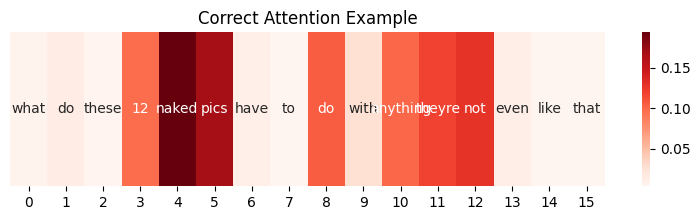

Sentence:
i think i may be finally in with the in crowd <UNK> <UNK>
True Label: positive
Predicted Label: neutral


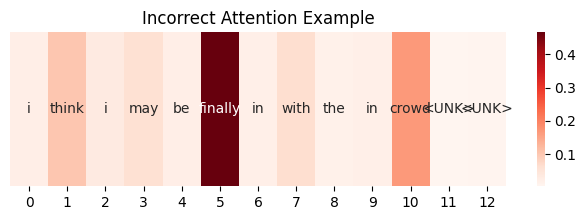

In [ ]:
reverse_label_mapping = {0: "negative", 1: "neutral", 2: "positive"}
index_to_word = {idx: word for word, idx in vocab.items()}

def visualize_attention(model, dataloader, correct=True):
    model.eval()

    with torch.no_grad():
        for inputs, labels in dataloader:
            logits, attention_weights = model(inputs, return_attention=True)
            preds = torch.argmax(logits, dim=1)

            for i in range(inputs.size(0)):
                is_correct = preds[i].item() == labels[i].item()

                if is_correct == correct:
                    token_ids = inputs[i].cpu().numpy()
                    weights = attention_weights[i].cpu().numpy()

                    tokens = []
                    selected_weights = []

                    for token_id, weight in zip(token_ids, weights):
                        if token_id != vocab["<PAD>"]:
                            tokens.append(index_to_word.get(token_id, "<UNK>"))
                            selected_weights.append(weight)

                    print("Sentence:")
                    print(" ".join(tokens))
                    print("True Label:", reverse_label_mapping[labels[i].item()])
                    print("Predicted Label:", reverse_label_mapping[preds[i].item()])

                    plt.figure(figsize=(max(8, len(tokens) * 0.6), 2))
                    sns.heatmap(
                        [selected_weights],
                        annot=[tokens],
                        fmt="",
                        cmap="Reds",
                        cbar=True
                    )
                    plt.yticks([])
                    plt.title(
                        "Correct Attention Example"
                        if correct else
                        "Incorrect Attention Example"
                    )
                    plt.show()

                    return

visualize_attention(attention_model, test_loader, correct=True)
visualize_attention(attention_model, test_loader, correct=False)

### Part **4**


Testing Transformer config: {'heads': 2, 'dropout': 0.3, 'lr': 0.001, 'epochs': 5, 'ff_dim': 128}

Training Transformer Encoder
Epoch [1/5], Training Loss: 0.3233, Time: 5.43s
Epoch [2/5], Training Loss: 0.1928, Time: 4.94s
Epoch [3/5], Training Loss: 0.1394, Time: 3.89s
Epoch [4/5], Training Loss: 0.1134, Time: 3.93s
Epoch [5/5], Training Loss: 0.0971, Time: 4.36s
Average training time per epoch: 4.51s

--- Evaluation Results on Transformer Dev Set ---
              precision    recall  f1-score   support

    negative     0.4257    0.4776    0.4502       312
     neutral     0.5980    0.5581    0.5774       869
    positive     0.6246    0.6398    0.6321       819

    accuracy                         0.5790      2000
   macro avg     0.5494    0.5585    0.5532      2000
weighted avg     0.5820    0.5790    0.5799      2000

Confusion Matrix:
[[149 108  55]
 [124 485 260]
 [ 77 218 524]]


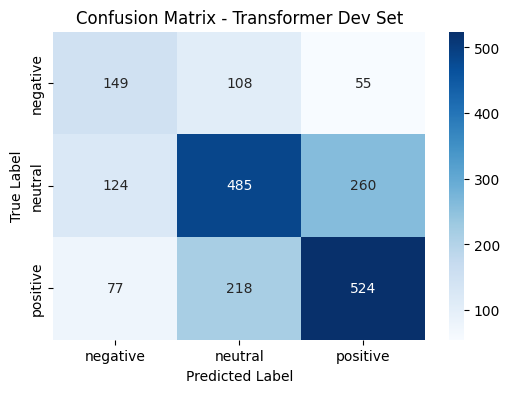


Testing Transformer config: {'heads': 2, 'dropout': 0.5, 'lr': 0.0005, 'epochs': 5, 'ff_dim': 256}

Training Transformer Encoder
Epoch [1/5], Training Loss: 0.3873, Time: 4.27s
Epoch [2/5], Training Loss: 0.2701, Time: 3.86s
Epoch [3/5], Training Loss: 0.2093, Time: 4.14s
Epoch [4/5], Training Loss: 0.1758, Time: 4.62s
Epoch [5/5], Training Loss: 0.1528, Time: 3.85s
Average training time per epoch: 4.15s

--- Evaluation Results on Transformer Dev Set ---
              precision    recall  f1-score   support

    negative     0.4417    0.5096    0.4732       312
     neutral     0.6036    0.5731    0.5880       869
    positive     0.6331    0.6300    0.6316       819

    accuracy                         0.5865      2000
   macro avg     0.5595    0.5709    0.5643      2000
weighted avg     0.5904    0.5865    0.5879      2000

Confusion Matrix:
[[159 105  48]
 [120 498 251]
 [ 81 222 516]]


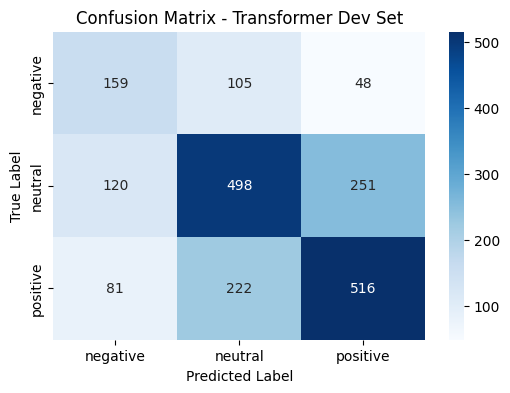


Testing Transformer config: {'heads': 4, 'dropout': 0.3, 'lr': 0.001, 'epochs': 10, 'ff_dim': 128}

Training Transformer Encoder
Epoch [1/10], Training Loss: 0.2607, Time: 4.03s
Epoch [2/10], Training Loss: 0.1288, Time: 4.85s
Epoch [3/10], Training Loss: 0.0918, Time: 4.24s
Epoch [4/10], Training Loss: 0.0711, Time: 3.97s
Epoch [5/10], Training Loss: 0.0602, Time: 5.00s
Epoch [6/10], Training Loss: 0.0532, Time: 3.88s
Epoch [7/10], Training Loss: 0.0518, Time: 3.86s
Epoch [8/10], Training Loss: 0.0410, Time: 4.81s
Epoch [9/10], Training Loss: 0.0399, Time: 3.98s
Epoch [10/10], Training Loss: 0.0363, Time: 3.87s
Average training time per epoch: 4.25s

--- Evaluation Results on Transformer Dev Set ---
              precision    recall  f1-score   support

    negative     0.4232    0.4679    0.4444       312
     neutral     0.5698    0.5305    0.5495       869
    positive     0.5969    0.6166    0.6066       819

    accuracy                         0.5560      2000
   macro avg     

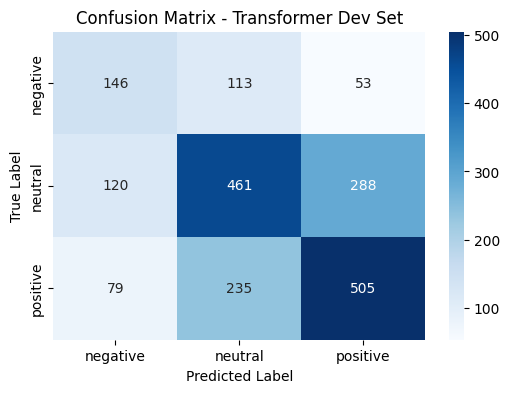


Testing Transformer config: {'heads': 4, 'dropout': 0.5, 'lr': 0.0005, 'epochs': 10, 'ff_dim': 256}

Training Transformer Encoder
Epoch [1/10], Training Loss: 0.3420, Time: 4.39s
Epoch [2/10], Training Loss: 0.1691, Time: 4.52s
Epoch [3/10], Training Loss: 0.1284, Time: 3.98s
Epoch [4/10], Training Loss: 0.1049, Time: 4.18s
Epoch [5/10], Training Loss: 0.0835, Time: 5.27s
Epoch [6/10], Training Loss: 0.0696, Time: 4.02s
Epoch [7/10], Training Loss: 0.0619, Time: 4.30s
Epoch [8/10], Training Loss: 0.0560, Time: 4.97s
Epoch [9/10], Training Loss: 0.0527, Time: 4.03s
Epoch [10/10], Training Loss: 0.0468, Time: 3.99s
Average training time per epoch: 4.37s

--- Evaluation Results on Transformer Dev Set ---
              precision    recall  f1-score   support

    negative     0.4338    0.4519    0.4427       312
     neutral     0.5805    0.5811    0.5808       869
    positive     0.6137    0.6032    0.6084       819

    accuracy                         0.5700      2000
   macro avg    

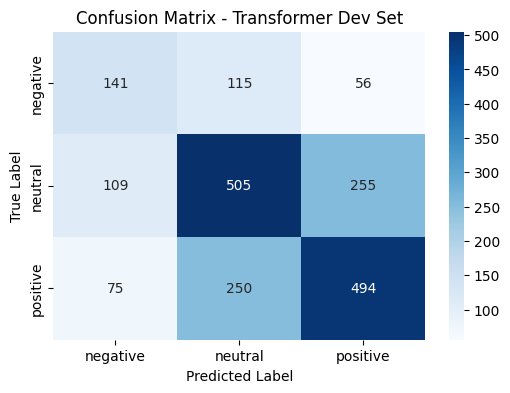

,Heads,Dropout,Learning Rate,Epochs,FF Dim,Dev Accuracy,Dev Macro F1,Avg Time/Epoch,Params
0,2,0.3,0.0010,5,128,0.5790,0.553206,4.509436,2154531
1,2,0.5,0.0005,5,256,0.5865,0.564250,4.147877,2180259
2,4,0.3,0.0010,10,128,0.5560,0.533505,4.249041,2154531
3,4,0.5,0.0005,10,256,0.5700,0.543956,4.366262,2180259


Best Transformer Config:
Heads             2.000000e+00
Dropout           5.000000e-01
Learning Rate     5.000000e-04
Epochs            5.000000e+00
FF Dim            2.560000e+02
Dev Accuracy      5.865000e-01
Dev Macro F1      5.642502e-01
Avg Time/Epoch    4.147877e+00
Params            2.180259e+06
Name: 1, dtype: float64


In [ ]:
def count_trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

class TransformerEncoderBlock(nn.Module):
    def __init__(self, embedding_dim, num_heads, ff_dim, dropout_rate):
        super(TransformerEncoderBlock, self).__init__()

        self.self_attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            dropout=dropout_rate,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(embedding_dim)
        self.norm2 = nn.LayerNorm(embedding_dim)

        self.feed_forward = nn.Sequential(
            nn.Linear(embedding_dim, ff_dim),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(ff_dim, embedding_dim)
        )

        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x, padding_mask):
        attention_output, attention_weights = self.self_attention(
            x,
            x,
            x,
            key_padding_mask=padding_mask
        )

        x = self.norm1(x + self.dropout(attention_output))

        ff_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ff_output))

        return x

class TransformerSentimentClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        output_size,
        max_len,
        pretrained_embeddings,
        num_heads,
        ff_dim,
        dropout_rate,
        num_layers=1
    ):
        super(TransformerSentimentClassifier, self).__init__()

        self.max_len = max_len
        self.embedding_dim = embedding_dim

        self.embedding = nn.Embedding.from_pretrained(
            pretrained_embeddings,
            freeze=False
        )

        self.position_embedding = nn.Embedding(max_len, embedding_dim)

        self.encoder_layers = nn.ModuleList([
            TransformerEncoderBlock(
                embedding_dim=embedding_dim,
                num_heads=num_heads,
                ff_dim=ff_dim,
                dropout_rate=dropout_rate
            )
            for _ in range(num_layers)
        ])

        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(embedding_dim, output_size)

    def forward(self, x):
        batch_size, seq_len = x.size()

        token_embeddings = self.embedding(x)

        positions = torch.arange(seq_len, device=x.device).unsqueeze(0)
        position_embeddings = self.position_embedding(positions)

        z = token_embeddings + position_embeddings

        padding_mask = (x == 0)

        encoder_output = z
        for layer in self.encoder_layers:
            encoder_output = layer(encoder_output, padding_mask)

        mask = (x != 0).unsqueeze(-1).float()
        encoder_output = encoder_output * mask

        lengths = mask.sum(dim=1).clamp(min=1)
        pooled = encoder_output.sum(dim=1) / lengths

        out = self.dropout(pooled)
        logits = self.fc(out)

        return logits

def train_transformer_model(model, train_loader, criterion, optimizer, num_epochs):
    model.to(device)
    epoch_times = []

    print("\nTraining Transformer Encoder")

    for epoch in range(num_epochs):
        start_time = time.time()
        model.train()
        total_loss = 0

        for inputs, labels in train_loader:
            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            total_loss += loss.item()

        epoch_time = time.time() - start_time
        epoch_times.append(epoch_time)

        print(
            f"Epoch [{epoch+1}/{num_epochs}], "
            f"Training Loss: {total_loss / len(train_loader):.4f}, "
            f"Time: {epoch_time:.2f}s"
        )

    avg_time = sum(epoch_times) / len(epoch_times)
    print(f"Average training time per epoch: {avg_time:.2f}s")
    return avg_time

def evaluate_transformer_model(model, dataloader, dataset_name):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    target_names = ["negative", "neutral", "positive"]

    print(f"\n--- Evaluation Results on {dataset_name} Set ---")

    report = classification_report(
        all_labels,
        all_preds,
        target_names=target_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )

    print(classification_report(
        all_labels,
        all_preds,
        target_names=target_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(all_labels, all_preds)

    print("Confusion Matrix:")
    print(cm)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"Confusion Matrix - {dataset_name} Set")
    plt.show()

    return report, cm

transformer_configs = [
    {"heads": 2, "dropout": 0.3, "lr": 0.001, "epochs": 5, "ff_dim": 128},
    {"heads": 2, "dropout": 0.5, "lr": 0.0005, "epochs": 5, "ff_dim": 256},
    {"heads": 4, "dropout": 0.3, "lr": 0.001, "epochs": 10, "ff_dim": 128},
    {"heads": 4, "dropout": 0.5, "lr": 0.0005, "epochs": 10, "ff_dim": 256},
]

transformer_tuning_results = []

for cfg in transformer_configs:
    print("\nTesting Transformer config:", cfg)

    temp_transformer = TransformerSentimentClassifier(
        vocab_size=len(vocab),
        embedding_dim=100,
        output_size=3,
        max_len=MAX_LEN,
        pretrained_embeddings=pretrained_embeddings,
        num_heads=cfg["heads"],
        ff_dim=cfg["ff_dim"],
        dropout_rate=cfg["dropout"],
        num_layers=1
    ).to(device)

    optimizer_temp = optim.Adam(temp_transformer.parameters(), lr=cfg["lr"])

    avg_time = train_transformer_model(
        temp_transformer,
        train_loader,
        criterion,
        optimizer_temp,
        num_epochs=cfg["epochs"]
    )

    report, _ = evaluate_transformer_model(
        temp_transformer,
        dev_loader,
        "Transformer Dev"
    )

    transformer_tuning_results.append({
        "Heads": cfg["heads"],
        "Dropout": cfg["dropout"],
        "Learning Rate": cfg["lr"],
        "Epochs": cfg["epochs"],
        "FF Dim": cfg["ff_dim"],
        "Dev Accuracy": report["accuracy"],
        "Dev Macro F1": report["macro avg"]["f1-score"],
        "Avg Time/Epoch": avg_time,
        "Params": count_trainable_params(temp_transformer)
    })

transformer_tuning_df = pd.DataFrame(transformer_tuning_results)
display(transformer_tuning_df)

best_transformer_config = transformer_tuning_df.sort_values(
    "Dev Macro F1",
    ascending=False
).iloc[0]

print("Best Transformer Config:")
print(best_transformer_config)


Training Transformer Encoder
Epoch [1/5], Training Loss: 0.3779, Time: 5.02s
Epoch [2/5], Training Loss: 0.2199, Time: 4.29s
Epoch [3/5], Training Loss: 0.1541, Time: 3.93s
Epoch [4/5], Training Loss: 0.1224, Time: 4.90s
Epoch [5/5], Training Loss: 0.1068, Time: 3.78s
Average training time per epoch: 4.38s

--- Evaluation Results on Development Set ---
              precision    recall  f1-score   support

    negative     0.4116    0.5000    0.4515       312
     neutral     0.5952    0.5144    0.5519       869
    positive     0.6057    0.6435    0.6240       819

    accuracy                         0.5650      2000
   macro avg     0.5375    0.5526    0.5425      2000
weighted avg     0.5709    0.5650    0.5658      2000

Confusion Matrix:
[[156 102  54]
 [133 447 289]
 [ 90 202 527]]


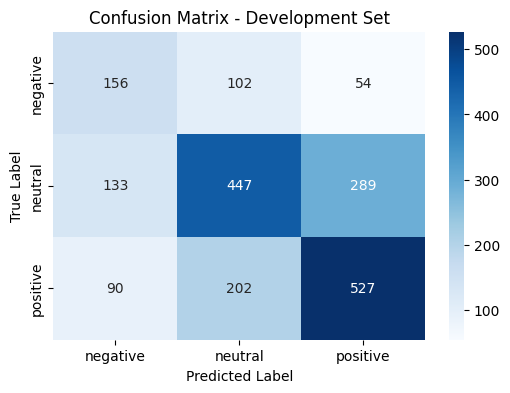


--- Evaluation Results on Test Set ---
              precision    recall  f1-score   support

    negative     0.5129    0.4791    0.4954      3972
     neutral     0.5728    0.4954    0.5313      5937
    positive     0.3887    0.5629    0.4598      2375

    accuracy                         0.5032     12284
   macro avg     0.4915    0.5125    0.4955     12284
weighted avg     0.5179    0.5032    0.5059     12284

Confusion Matrix:
[[1903 1474  595]
 [1488 2941 1508]
 [ 319  719 1337]]


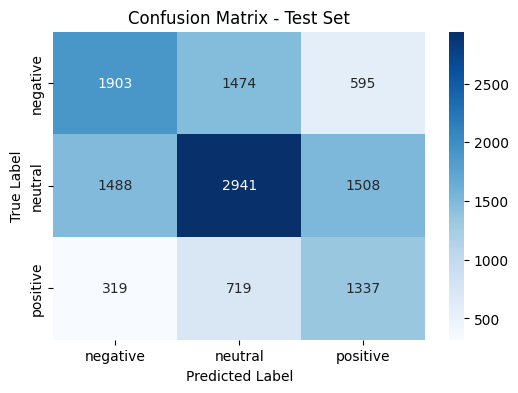

Transformer trainable parameters: 2180259
Learned positional embedding size: torch.Size([80, 100])


In [ ]:
TRANSFORMER_HEADS = int(best_transformer_config["Heads"])
TRANSFORMER_DROPOUT = float(best_transformer_config["Dropout"])
TRANSFORMER_LR = float(best_transformer_config["Learning Rate"])
TRANSFORMER_EPOCHS = int(best_transformer_config["Epochs"])
TRANSFORMER_FF_DIM = int(best_transformer_config["FF Dim"])

transformer_model = TransformerSentimentClassifier(
    vocab_size=len(vocab),
    embedding_dim=100,
    output_size=3,
    max_len=MAX_LEN,
    pretrained_embeddings=pretrained_embeddings,
    num_heads=TRANSFORMER_HEADS,
    ff_dim=TRANSFORMER_FF_DIM,
    dropout_rate=TRANSFORMER_DROPOUT,
    num_layers=1
).to(device)

optimizer_transformer = optim.Adam(
    transformer_model.parameters(),
    lr=TRANSFORMER_LR
)

transformer_avg_time = train_transformer_model(
    transformer_model,
    train_loader,
    criterion,
    optimizer_transformer,
    num_epochs=TRANSFORMER_EPOCHS
)

transformer_dev_report, transformer_dev_cm = evaluate_transformer_model(
    transformer_model,
    dev_loader,
    "Development"
)

transformer_test_report, transformer_test_cm = evaluate_transformer_model(
    transformer_model,
    test_loader,
    "Test"
)

transformer_params = count_trainable_params(transformer_model)

print("Transformer trainable parameters:", transformer_params)
print("Learned positional embedding size:", transformer_model.position_embedding.weight.shape)

In [ ]:
bilstm_family_rows = []

bilstm_family_rows.append({
    "Model": "BiLSTM",
    "Dev Report": bilstm_dev_report,
    "Test Report": bilstm_test_report,
    "Avg Time/Epoch": bilstm_avg_time,
    "Params": count_trainable_params(bilstm_model)
})

bilstm_family_rows.append({
    "Model": "BiLSTM + Attention",
    "Dev Report": attention_dev_report,
    "Test Report": attention_test_report,
    "Avg Time/Epoch": attention_avg_time,
    "Params": count_trainable_params(attention_model)
})

best_bilstm_based = max(
    bilstm_family_rows,
    key=lambda row: row["Dev Report"]["macro avg"]["f1-score"]
)

print("Best BiLSTM-based model:", best_bilstm_based["Model"])

Best BiLSTM-based model: BiLSTM + Attention


In [ ]:
best_bilstm_dev_metrics = extract_metrics(best_bilstm_based["Dev Report"])
best_bilstm_test_metrics = extract_metrics(best_bilstm_based["Test Report"])

transformer_dev_metrics = extract_metrics(transformer_dev_report)
transformer_test_metrics = extract_metrics(transformer_test_report)

part4_comparison_data = [
    [best_bilstm_based["Model"] + " (Dev)",
     best_bilstm_dev_metrics["Accuracy"],
     best_bilstm_dev_metrics["Macro Precision"],
     best_bilstm_dev_metrics["Macro Recall"],
     best_bilstm_dev_metrics["Macro F1"],
     best_bilstm_based["Params"],
     round(best_bilstm_based["Avg Time/Epoch"], 2)],

    [best_bilstm_based["Model"] + " (Test)",
     best_bilstm_test_metrics["Accuracy"],
     best_bilstm_test_metrics["Macro Precision"],
     best_bilstm_test_metrics["Macro Recall"],
     best_bilstm_test_metrics["Macro F1"],
     best_bilstm_based["Params"],
     round(best_bilstm_based["Avg Time/Epoch"], 2)],

    ["Transformer (Dev)",
     transformer_dev_metrics["Accuracy"],
     transformer_dev_metrics["Macro Precision"],
     transformer_dev_metrics["Macro Recall"],
     transformer_dev_metrics["Macro F1"],
     transformer_params,
     round(transformer_avg_time, 2)],

    ["Transformer (Test)",
     transformer_test_metrics["Accuracy"],
     transformer_test_metrics["Macro Precision"],
     transformer_test_metrics["Macro Recall"],
     transformer_test_metrics["Macro F1"],
     transformer_params,
     round(transformer_avg_time, 2)]
]

part4_columns = [
    "Model",
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Trainable Params",
    "Avg Time/Epoch"
]

part4_comparison_df = pd.DataFrame(part4_comparison_data, columns=part4_columns)

print("\n=== Part 4: Best BiLSTM-Based Model vs Transformer ===")
display(part4_comparison_df)


=== Part 4: Best BiLSTM-Based Model vs Transformer ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Trainable Params,Avg Time/Epoch
0,BiLSTM + Attention (Dev),0.5775,0.5507,0.5568,0.5534,2332403,4.79
1,BiLSTM + Attention (Test),0.5090,0.4973,0.5143,0.5000,2332403,4.79
2,Transformer (Dev),0.5650,0.5375,0.5526,0.5425,2180259,4.38
3,Transformer (Test),0.5032,0.4915,0.5125,0.4955,2180259,4.38


### **Part 5**

In [ ]:
def get_class_f1(report, class_name):
    return round(report[class_name]["f1-score"], 4)

def get_summary_row(model_name, dev_report, test_report, model, avg_time):
    return {
        "Model": model_name,

        "Dev Accuracy": round(dev_report["accuracy"], 4),
        "Dev Macro Precision": round(dev_report["macro avg"]["precision"], 4),
        "Dev Macro Recall": round(dev_report["macro avg"]["recall"], 4),
        "Dev Macro F1": round(dev_report["macro avg"]["f1-score"], 4),

        "Test Accuracy": round(test_report["accuracy"], 4),
        "Test Macro Precision": round(test_report["macro avg"]["precision"], 4),
        "Test Macro Recall": round(test_report["macro avg"]["recall"], 4),
        "Test Macro F1": round(test_report["macro avg"]["f1-score"], 4),

        "Test Negative F1": get_class_f1(test_report, "negative"),
        "Test Neutral F1": get_class_f1(test_report, "neutral"),
        "Test Positive F1": get_class_f1(test_report, "positive"),

        "Trainable Params": count_trainable_params(model),
        "Avg Time/Epoch": round(avg_time, 2)
    }

final_summary_data = [
    get_summary_row("LSTM", lstm_dev_report, lstm_test_report, lstm_model, lstm_avg_time),
    get_summary_row("BiLSTM", bilstm_dev_report, bilstm_test_report, bilstm_model, bilstm_avg_time),
    get_summary_row("BiRNN", birnn_dev_report, birnn_test_report, birnn_model, birnn_avg_time),
    get_summary_row("BiLSTM + Attention", attention_dev_report, attention_test_report, attention_model, attention_avg_time),
    get_summary_row("Transformer", transformer_dev_report, transformer_test_report, transformer_model, transformer_avg_time)
]

final_summary_df = pd.DataFrame(final_summary_data)

print("\n=== Final Summary Table: All Models ===")
display(final_summary_df)


=== Final Summary Table: All Models ===


,Model,Dev Accuracy,Dev Macro Precision,Dev Macro Recall,Dev Macro F1,Test Accuracy,Test Macro Precision,Test Macro Recall,Test Macro F1,Test Negative F1,Test Neutral F1,Test Positive F1,Trainable Params,Avg Time/Epoch
0,LSTM,0.5745,0.5453,0.5568,0.5499,0.5044,0.4929,0.5110,0.4955,0.4884,0.5370,0.4612,2197747,3.03
1,BiLSTM,0.5760,0.5488,0.5580,0.5528,0.5116,0.4997,0.5175,0.5030,0.5043,0.5407,0.4640,2315891,4.77
2,BiRNN,0.5765,0.5479,0.5627,0.5531,0.5049,0.4941,0.5183,0.5003,0.5145,0.5153,0.4710,2139251,2.86
3,BiLSTM + Attention,0.5775,0.5507,0.5568,0.5534,0.5090,0.4973,0.5143,0.5000,0.4951,0.5408,0.4640,2332403,4.79
4,Transformer,0.5650,0.5375,0.5526,0.5425,0.5032,0.4915,0.5125,0.4955,0.4954,0.5313,0.4598,2180259,4.38


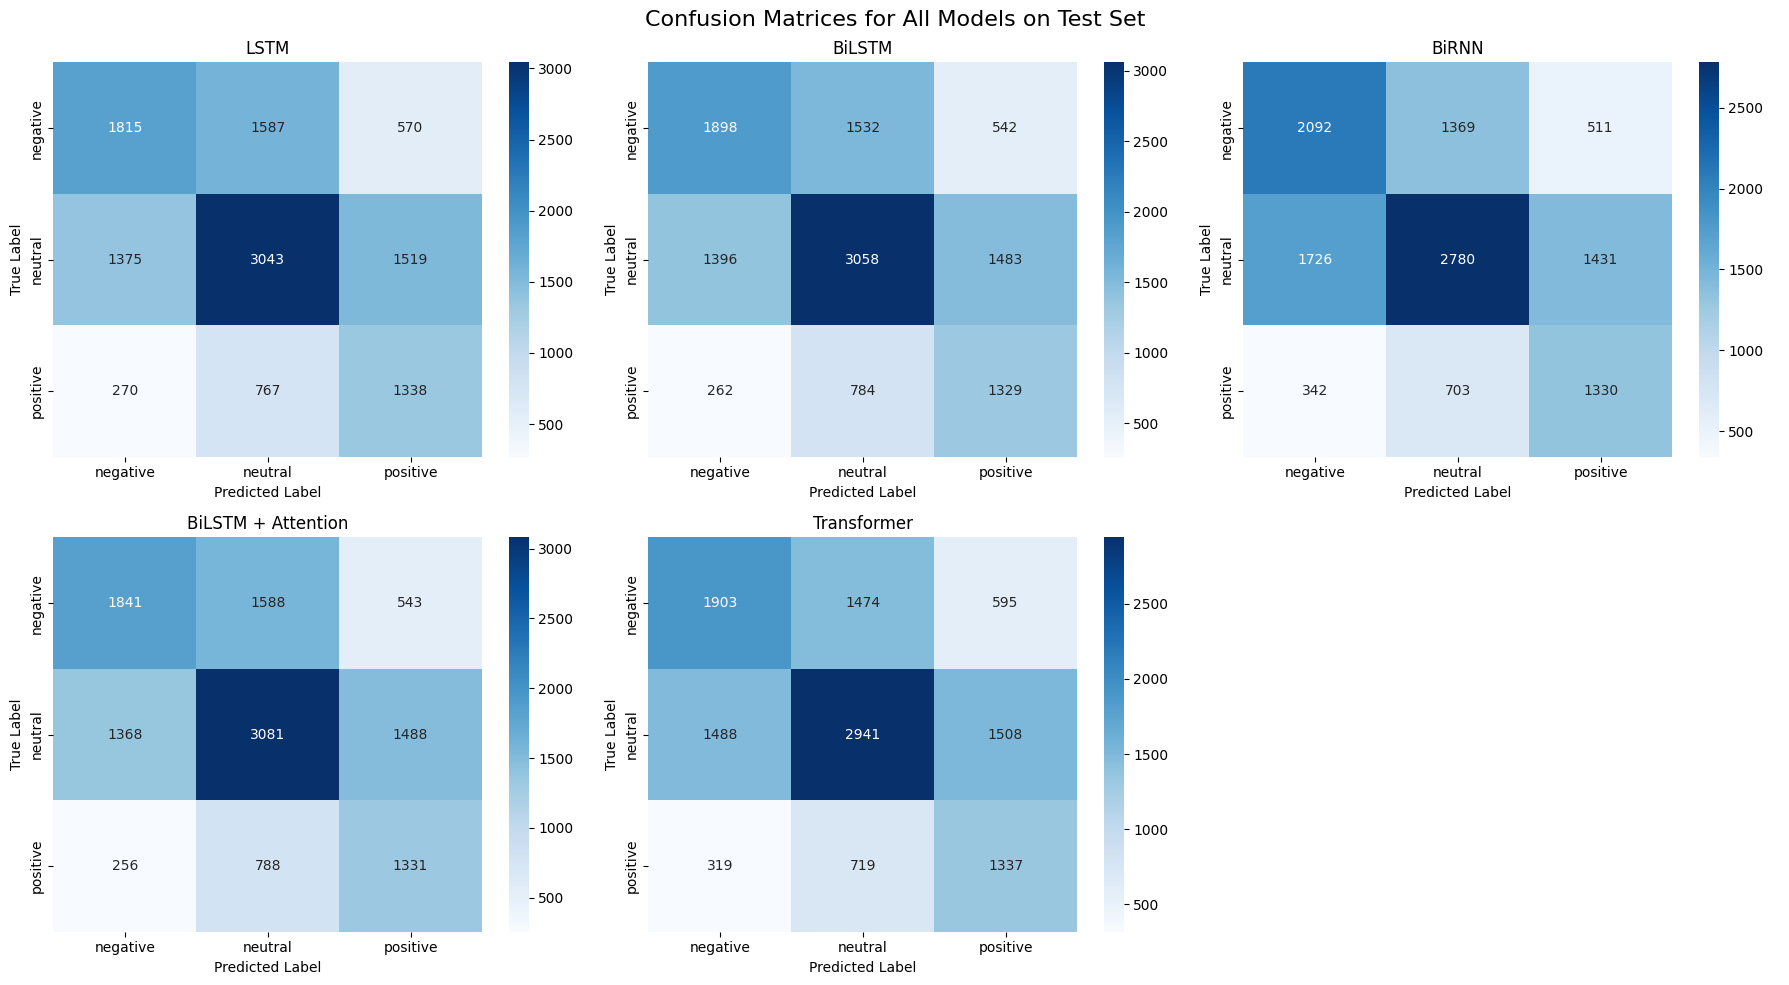

In [ ]:
cms = [
    ("LSTM", lstm_test_cm),
    ("BiLSTM", bilstm_test_cm),
    ("BiRNN", birnn_test_cm),
    ("BiLSTM + Attention", attention_test_cm),
    ("Transformer", transformer_test_cm)
]

target_names = ["negative", "neutral", "positive"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (model_name, cm) in enumerate(cms):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names,
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label")

axes[-1].axis("off")

plt.suptitle("Confusion Matrices for All Models on Test Set", fontsize=16)
plt.tight_layout()
plt.show()

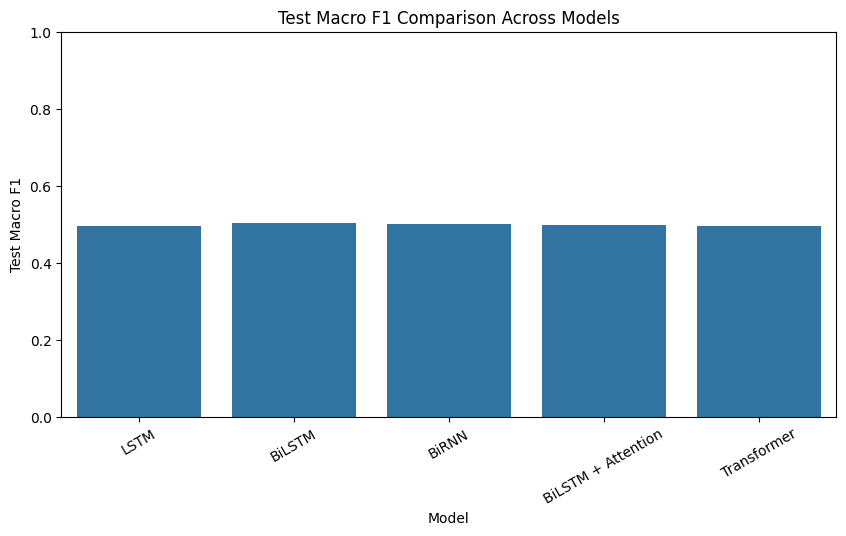

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=final_summary_df,
    x="Model",
    y="Test Macro F1"
)

plt.title("Test Macro F1 Comparison Across Models")
plt.ylabel("Test Macro F1")
plt.xlabel("Model")
plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.show()